# Whole-method memory on 100, saved timing on mdx

PR #4's sparse-operator reduction is measured through all three CLN stages on 100 (T7920). Each route/cohort gets a fresh Python process; mexcuda also gets its own fresh MATLAB Engine session. Original and condensed A-T, previous cached V/Phi and compact V/Phi are retained as controls.

Timing values below come exclusively from the accepted mdx NGSolve evidence in [notebook 26](26_compact_cln.ipynb). No 100-host performance timings are published. See [the memory contract](WHOLE_MEMORY100.md).

In [1]:
import json,statistics as st
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
base=Path('data') if Path('data').is_dir() else Path('docs/data')
memory=json.loads((base/'whole_memory100.json').read_text())
mdx=json.loads((base/'compact_cln_timing.json').read_text())
assert memory['complete'] and mdx['complete']
routes=['original','condensed','scalar-cached','scalar-compact','scalar-cached-mexcuda','scalar-compact-mexcuda']
labels=['A-T','Condensed A-T','Previous CPU','Compact CPU','Previous mexcuda','Compact mexcuda']
cohorts=[(c['maxh'],c['order']) for c in mdx['cohorts']]
def case(h,p,route):return next(x for x in memory['cases'] if (x['maxh'],x['order'],x['route'])==(h,p,route))
def table(head,rows):display(Markdown(' | '.join(head)+'\n'+' | '.join(['---']*len(head))+'\n'+'\n'.join(' | '.join(map(str,row)) for row in rows)))
print({k:memory[k] for k in ('host','host_role','python','ngsolve','numpy','radia','threads','blas_threads')})
print('Saved timing host:',mdx['runtime']['host'])
print('Memory cases:',len(memory['cases']))


{'host': 'T7920', 'host_role': '100', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'numpy': '2.5.3', 'radia': '5.2.3', 'threads': 4, 'blas_threads': 1}
Saved timing host: NGSolve
Memory cases: 24


## Process-family working sets and private commit

Requested sampling interval is 20 ms, starting before Engine launch and continuing through actual owned MATLAB exit. All observed descendants of the worker are included; other users' existing sessions are excluded by process ancestry. Summed RSS can double-count shared pages. Simultaneous sampled maxima can miss short spikes; sums of observed per-process native lifetime peaks are separate conservative upper sums, not simultaneous measurements. Worker import transients are represented in native lifetime counters. The common orchestration launcher and unrelated system services are outside this scope.

100 is a shared validation host. These are per-operation memory counters, not idle-host speed measurements.

Cohort | A-T MiB | Condensed A-T MiB | Previous CPU MiB | Compact CPU MiB | Previous mexcuda MiB | Compact mexcuda MiB
--- | --- | --- | --- | --- | --- | ---
p=2, h=3 mm | 163.62 | 144.98 | 186.36 | 171.36 | 2194.21 | 2177.69
p=3, h=3 mm | 211.83 | 174.39 | 373.12 | 296.96 | 2384.60 | 2308.50
p=3, h=2 mm | 295.68 | 305.23 | 858.14 | 629.44 | 2868.70 | 2636.52
p=4, h=3 mm | 316.89 | 285.50 | 926.43 | 660.11 | 2933.57 | 2665.42

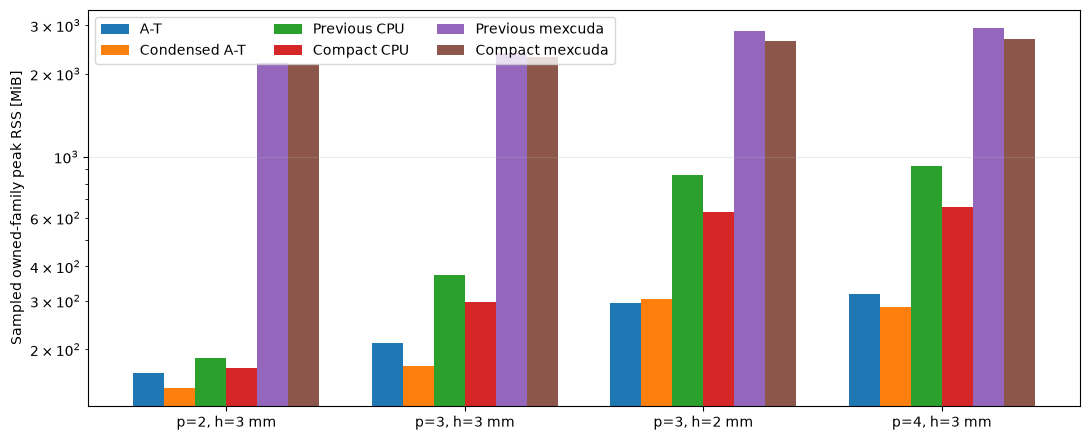

Cohort | Route | Joint RSS MiB | Joint private MiB | Native RSS peak sum MiB | Native private peak sum MiB
--- | --- | --- | --- | --- | ---
p=2, h=3 mm | original | 163.62 | 2870.14 | 165.05 | 2872.75
p=2, h=3 mm | condensed | 144.98 | 2856.76 | 145.98 | 2864.57
p=2, h=3 mm | scalar-cached | 186.36 | 2895.16 | 187.86 | 2904.78
p=2, h=3 mm | scalar-compact | 171.36 | 2880.16 | 172.46 | 2889.79
p=2, h=3 mm | scalar-cached-mexcuda | 2194.21 | 5761.05 | 2224.98 | 5780.86
p=2, h=3 mm | scalar-compact-mexcuda | 2177.69 | 5745.10 | 2209.36 | 5765.11
p=3, h=3 mm | original | 211.83 | 2918.50 | 224.24 | 2930.27
p=3, h=3 mm | condensed | 174.39 | 2884.71 | 191.25 | 2902.45
p=3, h=3 mm | scalar-cached | 373.12 | 3081.31 | 374.21 | 3090.93
p=3, h=3 mm | scalar-compact | 296.96 | 3004.57 | 298.26 | 3014.18
p=3, h=3 mm | scalar-cached-mexcuda | 2384.60 | 5880.25 | 2422.51 | 5918.06
p=3, h=3 mm | scalar-compact-mexcuda | 2308.50 | 5822.09 | 2345.14 | 5897.47
p=3, h=2 mm | original | 295.68 | 3001.89 | 373.28 | 3079.09
p=3, h=2 mm | condensed | 305.23 | 3015.91 | 342.30 | 3053.05
p=3, h=2 mm | scalar-cached | 858.14 | 3566.57 | 859.55 | 3576.08
p=3, h=2 mm | scalar-compact | 629.44 | 3338.50 | 630.76 | 3348.12
p=3, h=2 mm | scalar-cached-mexcuda | 2868.70 | 6408.02 | 2928.45 | 6459.57
p=3, h=2 mm | scalar-compact-mexcuda | 2636.52 | 6175.81 | 2738.84 | 6246.19
p=4, h=3 mm | original | 316.89 | 3022.38 | 407.45 | 3112.79
p=4, h=3 mm | condensed | 285.50 | 2996.13 | 301.89 | 3012.61
p=4, h=3 mm | scalar-cached | 926.43 | 3638.07 | 927.64 | 3647.67
p=4, h=3 mm | scalar-compact | 660.11 | 3368.03 | 661.32 | 3377.65
p=4, h=3 mm | scalar-cached-mexcuda | 2933.57 | 6503.72 | 2998.22 | 6558.86
p=4, h=3 mm | scalar-compact-mexcuda | 2665.42 | 6220.20 | 2730.11 | 6275.46

In [2]:
names=[];values=[];rows=[]
for h,p in cohorts:
 name=f"p={p}, h={h*1000:g} mm";names.append(name)
 values.append([case(h,p,route)['family']['joint_sampled_peak_rss']/2**20 for route in routes])
 rows.append([name]+[f'{x:.2f}' for x in values[-1]])
table(['Cohort']+[x+' MiB' for x in labels],rows)
fig,ax=plt.subplots(figsize=(11,4.5));x=np.arange(len(names));w=.13
for j,label in enumerate(labels):ax.bar(x+(j-2.5)*w,np.array(values)[:,j],w,label=label)
ax.set_xticks(x,names);ax.set_ylabel('Sampled owned-family peak RSS [MiB]');ax.set_yscale('log')
ax.legend(ncol=3);ax.grid(axis='y',alpha=.25);fig.tight_layout();plt.show()
rows=[]
for h,p in cohorts:
 for route in routes:
  f=case(h,p,route)['family']
  rows.append([f"p={p}, h={h*1000:g} mm",route]+[f'{f[k]/2**20:.2f}' for k in ('joint_sampled_peak_rss','joint_sampled_peak_private','observed_native_peak_sum_rss','observed_native_peak_sum_private')])
table(['Cohort','Route','Joint RSS MiB','Joint private MiB','Native RSS peak sum MiB','Native private peak sum MiB'],rows)


## Retained arrays and GPU allocation scope

The compact CSR reduction is a logical retained-array measure, not a whole-method memory ratio. Local dense projection arrays, scalar factors and runtime allocations remain. For mexcuda, reported device bytes cover the two owned MEX operator sets; they exclude CUDA context, MATLAB library pools and unmeasured device transients. Host RAM and VRAM are different resources and are not added.

In [3]:
rows=[]
for h,p in cohorts:
 old=case(h,p,'scalar-cached')['record'];new=case(h,p,'scalar-compact')['record']
 a=sum(old['cached_operator_csr_bytes_by_role'].values());b=sum(new['unique_operator_csr_bytes'].values())
 gpu=case(h,p,'scalar-compact-mexcuda')
 rows.append([f"p={p}, h={h*1000:g} mm",f'{a/2**20:.2f}',f'{b/2**20:.2f}',f'{100*(1-b/a):.1f}%',f"{sum(new['local_numpy_bytes_by_role'].values())/2**20:.2f}",f"{gpu['known_device_operator_bytes']/2**20:.2f}",gpu['device']])
table(['Cohort','Previous CSR MiB','Compact CSR MiB','CSR reduction','Local NumPy MiB','Known GPU operator MiB','100 GPU'],rows)


Cohort | Previous CSR MiB | Compact CSR MiB | CSR reduction | Local NumPy MiB | Known GPU operator MiB | 100 GPU
--- | --- | --- | --- | --- | --- | ---
p=2, h=3 mm | 27.69 | 11.90 | 57.0% | 10.29 | 5.42 | Quadro RTX 5000
p=3, h=3 mm | 136.82 | 59.74 | 56.3% | 47.36 | 24.31 | Quadro RTX 5000
p=3, h=2 mm | 404.33 | 176.63 | 56.3% | 142.01 | 72.85 | Quadro RTX 5000
p=4, h=3 mm | 476.69 | 210.57 | 55.8% | 158.54 | 80.45 | Quadro RTX 5000

## Time comparison uses saved mdx results

All entries are warmed medians of complete recursions from the unchanged accepted mdx JSON: setup, all stages, transfers and mandatory checks included. No memory-run elapsed times enter this table. MATLAB/GPU startup remains separately reported in notebooks 24 and 26.

In [4]:
rows=[]
for c in mdx['cohorts']:
 times=[st.median(r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']>0) for route in routes]
 rows.append([f"p={c['order']}, h={c['maxh']*1000:g} mm"]+[f'{x:.4f}' for x in times])
table(['Cohort']+[x+' [s]' for x in labels],rows)


Cohort | A-T [s] | Condensed A-T [s] | Previous CPU [s] | Compact CPU [s] | Previous mexcuda [s] | Compact mexcuda [s]
--- | --- | --- | --- | --- | --- | ---
p=2, h=3 mm | 1.2055 | 1.1419 | 2.5156 | 2.5011 | 2.1771 | 2.4080
p=3, h=3 mm | 3.3327 | 2.2864 | 5.7522 | 5.4909 | 5.1336 | 4.7663
p=3, h=2 mm | 8.7592 | 6.3413 | 18.5026 | 17.5637 | 14.1726 | 13.1610
p=4, h=3 mm | 8.7001 | 4.5173 | 15.5721 | 13.9335 | 13.7422 | 11.8714

## Accuracy and completion

All seven field modes and coefficients are compared with the saved same-mesh mdx A-T reference. This memory lane checks sampled vector RMS and integrated mode energies, plus the unchanged original scalar/physical residual, divergence, curl-fit and direct integrated curl-error gates. Full volume-vector parity is already retained in the accepted mdx experiment using the same numerical producers.

In [5]:
coeff=[];fields=[];energies=[]
for c in memory['cases']:
 cohort=next(x for x in mdx['cohorts'] if (x['maxh'],x['order'])==(c['maxh'],c['order']))
 ref=next(x for x in cohort['repeats'] if x['route']=='original');row=c['record']
 coeff.extend(abs(np.array(row['coefficients'])/ref['coefficients']-1))
 a,b=np.array(row['mode_samples']),np.array(ref['mode_samples'])
 fields.extend(np.linalg.norm((a-b).reshape(7,-1),axis=1)/np.linalg.norm(b.reshape(7,-1),axis=1))
 energies.extend(abs(np.array(row['mode_norm2'])/ref['mode_norm2']-1))
print('Maximum coefficient difference:',max(coeff))
print('Maximum sampled-vector RMS difference:',max(fields))
print('Maximum integrated mode-energy difference:',max(energies))
print('Sampler errors:',sum(len(c['family']['errors']) for c in memory['cases']))


Maximum coefficient difference: 1.2116718739463295e-10
Maximum sampled-vector RMS difference: 4.73381583124973e-09
Maximum integrated mode-energy difference: 1.2117107317521914e-10
Sampler errors: 0


This completes the new 100-host memory comparison. The earlier interrupted mdx audit remains historical partial evidence; its remote raw-log recovery and scratch cleanup still await the next user-started VM session. Scope is the homogeneous, simply connected, zero-shift curved-mesh internal wire. C2 independent T–Omega, loss FEM convergence and F2/Radia API migration remain open. Results are Codex self-review, not independent scientific acceptance.